# EN4554 Assignment 2: CNNs

**Name:** Kodithuwakku T N   **Index:** 220325X  

**Acknowledgement of AI tool use:** I used Claude to help write the code and to draft the structure of this notebook. I have read, run and understood every cell, tuned the settings myself, and checked every interpretation against the results that I obtained

**Setup:** PyTorch, CIFAR-10 (45k train / 5k validation split, per-channel normalisation with training statistics, fixed seed). The test set is used only once, in Task 4.

In [2]:
import copy
import math
import random
import time
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset, TensorDataset
from torchvision import datasets, transforms

SEED = 0

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Quadro RTX 5000


In [3]:
DATA_ROOT = './home/dhawala/thisuka/CNN_A02_DLV/data'   # already downloaded here
train=datasets.CIFAR10(root=DATA_ROOT, train=True, download=False, transform=transforms.ToTensor())
test=datasets.CIFAR10(root=DATA_ROOT, train=False, download=False, transform=transforms.ToTensor())

X=torch.tensor(train.data).permute(0,3,1,2).float()/255.0
Y=torch.tensor(train.targets)

Xtest=torch.tensor(test.data).permute(0,3,1,2).float()/255.0
Ytest=torch.tensor(test.targets)

perm = torch.randperm(50000, generator=torch.Generator().manual_seed(SEED))
tr_idx,val_idx = perm[:45000], perm[45000:]
Xtrain, Ytrain = X[tr_idx], Y[tr_idx]
Xval, Yval = X[val_idx], Y[val_idx]

mean = Xtrain.mean(dim=(0,2,3), keepdim=True)
std = Xtrain.std(dim=(0,2,3), keepdim=True)
norm=lambda x: (x-mean)/std
Xtrain, Xval, Xtest = norm(Xtrain), norm(Xval), norm(Xtest)
print("Xtrain:", Xtrain.shape, "Ytrain:", Ytrain.shape,mean.flatten(),std.flatten())




Xtrain: torch.Size([45000, 3, 32, 32]) Ytrain: torch.Size([45000]) tensor([0.4912, 0.4820, 0.4464]) tensor([0.2472, 0.2436, 0.2617])


## Task 1: Backpropagation
**(a)** `Linear`, `ReLU`, `Sigmoid` and softmax cross-entropy with explicit forward/backward (in the cells above), assembled into an `MLP`.

**Theory (1a): layers, loss and backpropagation.** The network is a composition $\hat Z=f_L\circ\cdots\circ f_1(X)$. The forward pass stores what each layer needs, and the backward pass applies the chain rule in reverse order: each layer receives the upstream gradient $G=\partial L/\partial Y$ and returns $\partial L/\partial X$ (plus the gradients of its own parameters). For a mini-batch $X\in\mathbb R^{N\times d}$:



* **Linear layer** $Y = XW + b$:
$$\frac{\partial L}{\partial W}=X^\top G,\qquad \frac{\partial L}{\partial b}=\sum_{i=1}^{N} G_{i,:},\qquad \frac{\partial L}{\partial X}=G\,W^\top .$$


In [4]:
class Linear:
    def __init__(self,i,o,g,std,dtype=torch.float32):
        self.W=torch.randn(i,o,generator=g,dtype=dtype)*std
        self.b=torch.zeros(o,dtype=dtype)
    def forward(self,x):
        self.x=x
        return x@self.W+self.b
    def backward(self,dout):
        self.dW=self.x.T@dout
        self.db=dout.sum(0)
        return dout@self.W.T
    def params(self):
        return [(self.W, "dW"), (self.b, "db")]

* **ReLU** $Y=\max(0,X)$:
 $\dfrac{\partial L}{\partial X}=G\odot \mathbf 1[X>0]$ (the gradient passes only where the unit was active).


In [5]:
class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return x * self.mask
    def backward(self, d): return d * self.mask
    def params(self): return []

* **Sigmoid** $\sigma(x)=\dfrac{1}{1+e^{-x}}$, with $\sigma'(x)=\sigma(x)\big(1-\sigma(x)\big)\le \tfrac14$: $\dfrac{\partial L}{\partial X}=G\odot\sigma(X)\odot\big(1-\sigma(X)\big)$.


In [6]:
class Sigmoid:
    def forward(self, x):
        self.out = torch.sigmoid(x)
        return self.out
    def backward(self, d): return d * self.out * (1 - self.out)
    def params(self): return []

* **Softmax cross-entropy** on logits $Z$ with labels $y$:
$$p_{ik}=\frac{e^{z_{ik}}}{\sum_j e^{z_{ij}}},\qquad L=-\frac1N\sum_{i}\log p_{i,y_i},\qquad \frac{\partial L}{\partial Z}=\frac1N\big(P-\mathrm{onehot}(y)\big).$$

In [7]:
class SoftmaxCE:
    def forward(self, logits, y):
        self.y = y
        self.p = torch.softmax(logits, 1)
        return -torch.log(self.p[torch.arange(len(y)), y]).mean()
    def backward(self):
        d = self.p.clone()
        d[torch.arange(len(self.y)), self.y] -= 1
        return d / len(self.y)

In [8]:
class MLP:
    def __init__(self, dims, act="relu", seed=0, dtype=torch.float32):
        g = torch.Generator().manual_seed(seed)
        self.layers = []
        for k, (i, o) in enumerate(zip(dims[:-1], dims[1:])):
            std = (2/i)**0.5 if act == "relu" else (1/i)**0.5   # He / Xavier-like
            self.layers.append(Linear(i, o, g, std, dtype))
            if k < len(dims) - 2:
                self.layers.append(ReLU() if act == "relu" else Sigmoid())
        self.loss_fn = SoftmaxCE()
    def forward(self, x):
        for l in self.layers: x = l.forward(x)
        return x
    def loss(self, x, y): 
        return self.loss_fn.forward(self.forward(x), y)
    def backward(self):
        d = self.loss_fn.backward()
        for l in reversed(self.layers): d = l.backward(d)
    def linears(self): 
        return [l for l in self.layers if isinstance(l, Linear)]
    def parameters(self):
        return [p for l in self.linears() for p in (l.W, l.b)]
    def gradients(self):
        return [g for l in self.linears() for g in (l.dW, l.db)]
    def sgd_step(self, lr):
        for l in self.linears():
            l.W -= lr * l.dW
            l.b -= lr * l.db



**(b)** Gradient check against autograd and against centred finite differences (float64).

The gradient computed by my hand-written backward pass is checked against two independent references, using the same weights and the same batch of 16 images (in float64).

**1. Centred finite difference.** The partial derivative with respect to one weight $w$ is approximated by perturbing that weight up and down by a small $\varepsilon$ and re-evaluating the loss (two extra forward passes per entry):
$$\frac{\partial L}{\partial w}\;\approx\;\frac{L(w+\varepsilon)-L(w-\varepsilon)}{2\varepsilon},\qquad \varepsilon=10^{-6}.$$
This needs no backward pass at all, so it is independent of my backprop code, but it is slow: only 20 random entries of each weight and bias tensor are checked.

**2. Autograd.** PyTorch records the operations of the forward pass in a computation graph and applies the chain rule to it automatically (`loss.backward()`). The same network is rebuilt with `requires_grad=True` copies of my weights, so autograd returns the exact gradient (up to floating-point round-off) for **every** entry of every tensor. The two gradients are compared with `torch.allclose`.

**3. Error analysis.** The agreement between my gradient $g_a$ and a reference $g_b$ is measured by the relative error $\mathrm{rel.err}(g_a,g_b)=\dfrac{|g_a-g_b|}{|g_a|+|g_b|}$ (entry-wise; the maximum is reported), together with `torch.allclose`, which requires $|a-b|\le\text{atol}+\text{rtol}\,|b|$ for every entry. Against autograd the only difference is floating-point round-off, so the error should be close to machine precision. The finite difference is less accurate because of two errors: a Taylor expansion shows that the centred difference equals $L'(w)+\frac{\varepsilon^2}{6}L'''(w)+O(\varepsilon^4)$, so its truncation error is $O(\varepsilon^2)$, while subtracting two nearly equal loss values adds a round-off error of order $\epsilon_{\text{mach}}|L|/\varepsilon$ that grows as $\varepsilon$ shrinks. The total is smallest for $\varepsilon\approx\epsilon_{\text{mach}}^{1/3}$ (about $10^{-5}$ in float64), which is why float64 is used and $\varepsilon$ cannot simply be made tiny. A finite difference that straddles the kink of a ReLU can also disagree with the analytic gradient, but this is rare for random inputs.

In [9]:
def rel_err(a, b):
    return ((a - b).abs() / (a.abs() + b.abs()).clamp_min(1e-12)).max().item()

set_seed()
xb = Xtrain[:16].flatten(1).double(); yb = Ytrain[:16]
net = MLP([3072, 64, 32, 10], "relu", dtype=torch.float64)
net.loss(xb, yb); net.backward()

# autograd reference with identical weights
ps = [t.clone().requires_grad_() for t in net.parameters()]
h = xb
for k in range(0, len(ps), 2):
    h = h @ ps[k] + ps[k + 1]
    if k < len(ps) - 2: h = torch.relu(h)
F.cross_entropy(h, yb).backward()

# centred finite differences on random entries
def fd(param, idx, eps=1e-6):
    old = param[idx].item()
    param[idx] = old + eps; lp = net.loss(xb, yb).item()
    param[idx] = old - eps; lm = net.loss(xb, yb).item()
    param[idx] = old
    return (lp - lm) / (2 * eps)

details = []   # the exact gradient values behind each error (worst entry only)
print(f"{'param':8s} {'rel.err vs autograd':>20s} {'allclose':>9s} {'rel.err vs finite diff':>24s}")
for k, l in enumerate(net.linears()):
    for name, p, mine, ag in [("W", l.W, l.dW, ps[2*k].grad), ("b", l.b, l.db, ps[2*k+1].grad)]:
        idxs = [tuple(torch.randint(0, s, (1,)).item() for s in p.shape) for _ in range(20)]
        e_fd, worst = 0, None
        for i in idxs:
            f_ = fd(p, i); m_ = mine[i].item()
            e = abs(f_ - m_) / max(abs(f_) + abs(m_), 1e-12)
            if e >= e_fd: e_fd, worst = e, (i, m_, f_)
        print(f"{name+str(k):8s} {rel_err(mine, ag):20.2e} {str(torch.allclose(mine, ag)):>9s} {e_fd:24.2e}")
        # entry where backprop vs autograd is worst (over the whole tensor)
        r = (mine - ag).abs() / (mine.abs() + ag.abs()).clamp_min(1e-12)
        ja = tuple(int(v) for v in torch.unravel_index(r.argmax(), r.shape))
        details.append((name + str(k), ja, mine[ja].item(), ag[ja].item(), r[ja].item(), worst, e_fd))

print("\nExact values behind the errors above (worst entry of each tensor)")
print("autograd error: entry with the largest relative error over the whole tensor")
print(f"{'param':6s} {'entry':>12s} {'backprop (mine)':>18s} {'autograd':>18s} {'rel.err':>10s}")
for n_, ja, m_, a_, ea, _, _ in details:
    print(f"{n_:6s} {str(list(ja)):>12s} {m_:18.10e} {a_:18.10e} {ea:10.2e}")
print("\nfinite-difference error: worst of the 20 random entries checked")
print(f"{'param':6s} {'entry':>12s} {'backprop (mine)':>18s} {'finite diff':>18s} {'rel.err':>10s}")
for n_, _, _, _, _, (iw, m_, f_), ef in details:
    print(f"{n_:6s} {str(list(iw)):>12s} {m_:18.10e} {f_:18.10e} {ef:10.2e}")

param     rel.err vs autograd  allclose   rel.err vs finite diff
W0                   1.73e-11      True                 1.77e-08
b0                   2.45e-15      True                 5.37e-08
W1                   1.22e-14      True                 4.81e-08
b1                   5.76e-16      True                 2.65e-08
W2                   6.29e-15      True                 7.98e-07
b2                   5.04e-14      True                 8.73e-07

Exact values behind the errors above (worst entry of each tensor)
autograd error: entry with the largest relative error over the whole tensor
param         entry    backprop (mine)           autograd    rel.err
W0         [24, 50]   1.2503142531e-07   1.2503142530e-07   1.73e-11
b0             [51]   1.0613109072e-03   1.0613109072e-03   2.45e-15
W1         [43, 29]   3.5671123008e-05   3.5671123008e-05   1.22e-14
b1              [1]   6.0191247157e-03   6.0191247157e-03   5.76e-16
W2          [12, 5]   1.4651793763e-04   1.4651793763e-04

**Interpretation (1b).** The gradients from my explicit backward pass agree with autograd to between 1e-11 and 1e-15 relative error, and `torch.allclose` is `True` for every weight and bias. So the hand-written `Linear`, `ReLU` and softmax cross-entropy backward passes are correct up to float64 rounding. The agreement with centred finite differences is looser, between 1e-8 and 9e-7. This is expected: a finite difference has a truncation error of order ε² and a round-off error of order machine-epsilon/ε (here ε = 1e-6), so it cannot be as exact as an analytic gradient. It is still small enough to confirm that the formulas are right. Only 20 random entries per tensor were checked with finite differences.

**(c)** Train the MLP with plain SGD on flattened CIFAR-10 images (the explicit-backprop layers run on the GPU).

**Training the MLP with SGD.** The model is a 3072-512-256-10 MLP (about 1.7M parameters) acting on flattened pixels. The loss is the mean softmax cross-entropy defined in (1a). Mini-batch stochastic gradient descent estimates the gradient on a batch $B$ and updates all weights with
$$w \leftarrow w-\eta\,\nabla_w L_B(w),\qquad L_B=-\frac1{|B|}\sum_{i\in B}\log p_{i,y_i},$$
one pass over the 45k training images being one epoch. Weights are initialized as $W_{ij}\sim\mathcal N\!\big(0,\;2/n_{\text{in}}\big)$ (He initialization), which keeps the variance of the ReLU activations roughly constant from layer to layer; biases start at zero. Performance is measured by the validation accuracy
$$\mathrm{acc}=\frac1{N_v}\sum_{i=1}^{N_v}\mathbf 1\big[\arg\max_k z_{ik}=y_i\big]$$
on the 5k held-out images. A model with many more parameters than training examples can drive the training loss towards zero without improving the validation accuracy (overfitting), so both curves are monitored.

epoch  1  train loss 1.684  val acc 0.4374
epoch  2  train loss 1.410  val acc 0.4588
epoch  3  train loss 1.285  val acc 0.4844
epoch  4  train loss 1.179  val acc 0.4700
epoch  5  train loss 1.092  val acc 0.4992
epoch  6  train loss 1.011  val acc 0.4948
epoch  7  train loss 0.937  val acc 0.5034
epoch  8  train loss 0.868  val acc 0.4950
epoch  9  train loss 0.794  val acc 0.4920
epoch 10  train loss 0.734  val acc 0.4990
epoch 11  train loss 0.670  val acc 0.5016
epoch 12  train loss 0.614  val acc 0.4944
epoch 13  train loss 0.559  val acc 0.5032
epoch 14  train loss 0.502  val acc 0.5108
epoch 15  train loss 0.449  val acc 0.5082
epoch 16  train loss 0.407  val acc 0.4980
epoch 17  train loss 0.368  val acc 0.5066
epoch 18  train loss 0.334  val acc 0.4998
epoch 19  train loss 0.291  val acc 0.4858
epoch 20  train loss 0.253  val acc 0.5024


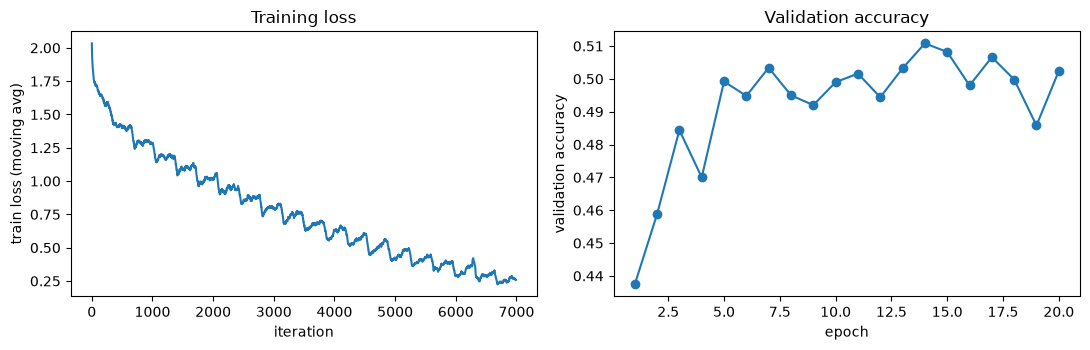

Final validation accuracy: 0.5024
Best validation accuracy:  0.5108 (epoch 14)


In [10]:
def mlp_to(net, dev):
    for l in net.linears():
        l.W = l.W.to(dev); l.b = l.b.to(dev)
    return net

def mlp_acc(net, X, Y):
    with torch.no_grad():
        return (net.forward(X.flatten(1)).argmax(1) == Y).float().mean().item()

Xtr_f, Ytr_g = Xtrain.flatten(1).to(device), Ytrain.to(device)
Xva_g, Yva_g = Xval.to(device), Yval.to(device)

set_seed()
net = mlp_to(MLP([3072, 512, 256, 10], "relu"), device)
lr, bs, epochs = 0.05, 128, 20
losses, val_accs = [], []
for ep in range(epochs):
    idx = torch.randperm(len(Xtr_f), device=device)
    for i in range(0, len(idx), bs):
        b = idx[i:i + bs]
        l = net.loss(Xtr_f[b], Ytr_g[b]); net.backward()
        net.sgd_step(lr)
        losses.append(l.item())
    val_accs.append(mlp_acc(net, Xva_g, Yva_g))
    print(f"epoch {ep+1:2d}  train loss {np.mean(losses[-(len(idx)//bs):]):.3f}  val acc {val_accs[-1]:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(np.convolve(losses, np.ones(50) / 50, mode="valid")); ax[0].set(xlabel="iteration", ylabel="train loss (moving avg)", title="Training loss")
ax[1].plot(range(1, epochs + 1), val_accs, "o-"); ax[1].set(xlabel="epoch", ylabel="validation accuracy", title="Validation accuracy")
plt.tight_layout(); plt.show()
print(f"Final validation accuracy: {val_accs[-1]:.4f}")
print(f"Best validation accuracy:  {max(val_accs):.4f} (epoch {int(np.argmax(val_accs))+1})")

**Interpretation (1c).** The training loss falls steadily from 1.68 to 0.25 over 20 epochs, but validation accuracy stops improving after about epoch 5 and stays near 50% (final 50.2%, best 51.1% at epoch 14). The widening gap between a falling training loss and flat validation accuracy shows that the MLP is overfitting: with about 1.7M parameters acting on raw flattened pixels, it memorises the training images instead of learning features that generalise. An MLP has no notion of spatial locality or translation invariance.

**(d)** Per-layer gradient norm at initialization in a 10-layer MLP (width 100), sigmoid vs ReLU.

**Gradient flow through depth.** Write $Z_\ell=H_{\ell-1}W_\ell+b_\ell$ and $H_\ell=\varphi(Z_\ell)$ for layers $\ell=1,\dots,L$ (here $L=10$). The backward signal at layer $\ell$ is
$$\delta_\ell=\frac{\partial L}{\partial Z_\ell}=\big(\delta_{\ell+1}W_{\ell+1}^\top\big)\odot\varphi'(Z_\ell),\qquad \frac{\partial L}{\partial W_\ell}=H_{\ell-1}^\top\delta_\ell .$$
Unrolling this recursion gives a product of $L-\ell$ factors of the form $W^\top\,\mathrm{diag}\,\varphi'(Z)$, so
$$\|\delta_\ell\|\;\lesssim\;\prod_{k>\ell}\|W_k\|\;\max|\varphi'|^{\,L-\ell}.$$
For the sigmoid $\max|\varphi'|=1/4$, so the signal shrinks roughly geometrically towards the input (**vanishing gradients**). For ReLU, $\varphi'\in\{0,1\}$ and with He initialization the second moment of the backward signal is preserved on average, so the norms stay roughly constant. The quantity plotted is the Frobenius norm $\big\|\partial L/\partial W_\ell\big\|_F$ of each layer's weight gradient at initialization, on one batch of 256 images.

sigmoid ['8.5e-06', '4.8e-06', '1.9e-05', '7.3e-05', '3.1e-04', '1.3e-03', '5.5e-03', '2.5e-02', '1.1e-01', '5.2e-01']
relu ['5.3e+00', '1.4e+00', '1.8e+00', '2.4e+00', '3.0e+00', '2.7e+00', '3.0e+00', '2.7e+00', '3.3e+00', '3.8e+00']


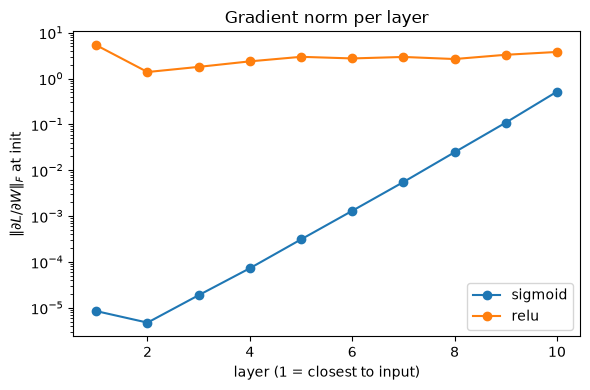

In [11]:
def layer_grad_norms(act, seed=0):
    set_seed(seed)
    n = MLP([3072] + [100] * 9 + [10], act)       # 10 Linear layers
    n.loss(Xtrain[:256].flatten(1), Ytrain[:256]); n.backward()
    return [l.dW.norm().item() for l in n.linears()]

plt.figure(figsize=(6, 4))
for act in ["sigmoid", "relu"]:
    g = layer_grad_norms(act)
    plt.semilogy(range(1, 11), g, "o-", label=act)
    print(act, ["%.1e" % v for v in g])
plt.xlabel("layer (1 = closest to input)"); plt.ylabel(r"$\|\partial L/\partial W\|_F$ at init"); plt.legend(); plt.title("Gradient norm per layer")
plt.tight_layout(); plt.show()

**Interpretation (1d).** With sigmoid, the gradient norm shrinks by roughly a factor of 4 at every layer going backwards, from 5.2e-1 at layer 10 to 8.5e-6 at layer 1, which is about five orders of magnitude. This is the vanishing gradient problem. The sigmoid derivative is at most 0.25, so each layer multiplies the backward signal by a small number, and the factors compound over 10 layers. The layers near the input therefore get almost no learning signal. With ReLU and He initialization the norms stay between about 1.4 and 5.3 with no systematic decay: the ReLU derivative is exactly 1 where the unit is active, and the He weight variance (2/fan_in) compensates for the units that are switched off. This is why ReLU networks can be trained when they are deep.

## Shared utilities for the CNN experiments (Tasks 2-4)
Data is kept on the GPU as tensors; `fit` is a plain training loop with optional augmentation, mixup, LR schedule and mixed precision.

In [12]:
Xtr_g, Ytr_g = Xtrain.to(device), Ytrain.to(device)
Xva_g, Yva_g = Xval.to(device), Yval.to(device)
Xte_g, Yte_g = Xtest.to(device), Ytest.to(device)      # only touched in Task 4

def evaluate(model, X, Y, bs=1000, amp=False):
    model.eval(); correct, loss = 0, 0.
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16, enabled=amp):
        for i in range(0, len(X), bs):
            out = model(X[i:i + bs])
            loss += F.cross_entropy(out.float(), Y[i:i + bs], reduction="sum").item()
            correct += (out.argmax(1) == Y[i:i + bs]).sum().item()
    return correct / len(X), loss / len(X)

def fit(model, opt, X, Y, epochs, bs=128, augment=None, mixup_alpha=0., sched=None, amp=False,
        track_train=False, label_smoothing=0., Xv=None, Yv=None, verbose=False):
    Xv = Xva_g if Xv is None else Xv; Yv = Yva_g if Yv is None else Yv
    model.to(device)
    scaler = torch.amp.GradScaler("cuda", enabled=amp)
    hist = dict(train_loss=[], val_acc=[], val_loss=[], train_acc=[])
    n = len(X)
    for ep in range(epochs):
        model.train(); tot = torch.zeros((), device=device)
        perm = torch.randperm(n, device=device)
        for i in range(0, n, bs):
            idx = perm[i:i + bs]; xb, yb = X[idx], Y[idx]
            if augment is not None: xb = augment(xb)
            if mixup_alpha > 0:
                xb, yb, yb2, lam = mixup_batch(xb, yb, mixup_alpha)      # defined in Task 3(a)
            with torch.autocast("cuda", dtype=torch.float16, enabled=amp):
                out = model(xb)
            out = out.float()
            if mixup_alpha > 0:
                loss = mixup_loss(out, yb, yb2, lam, label_smoothing)    # defined in Task 3(a)
            else:
                loss = F.cross_entropy(out, yb, label_smoothing=label_smoothing)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            if sched is not None: sched.step()
            tot += loss.detach() * len(idx)
        hist["train_loss"].append(tot.item() / n)
        va, vl = evaluate(model, Xv, Yv, amp=amp); hist["val_acc"].append(va); hist["val_loss"].append(vl)
        if track_train: hist["train_acc"].append(evaluate(model, X, Y, amp=amp)[0])
        if verbose: print(f"ep {ep+1:2d} loss {hist['train_loss'][-1]:.3f} val {va:.4f}")
    return hist

def small_cnn(bn=False, p_drop=0.):
    def blk(i, o):
        return [nn.Conv2d(i, o, 3, padding=1)] + ([nn.BatchNorm2d(o)] if bn else []) + [nn.ReLU(), nn.MaxPool2d(2)]
    return nn.Sequential(*blk(3, 32), *blk(32, 64), *blk(64, 128), nn.Flatten(),
                         nn.Linear(128 * 16, 256), nn.ReLU(), nn.Dropout(p_drop), nn.Linear(256, 10))

## Task 2: Optimizers
**(a)** SGD with momentum and Adam (with bias correction) written as `torch.optim.Optimizer` subclasses. Both follow the PyTorch conventions (`buf = mu*buf + g; p -= lr*buf` and the standard Adam update).

**The update rules** ($g_t=\nabla L(\theta_{t-1})$, learning rate $\eta$).

* **SGD:** $\theta_t=\theta_{t-1}-\eta\,g_t$.
* **SGD with momentum** (PyTorch convention): $v_t=\mu\,v_{t-1}+g_t,\qquad \theta_t=\theta_{t-1}-\eta\,v_t$. For a constant gradient, $v_t\to g/(1-\mu)$, so the effective step is $\eta/(1-\mu)$ (10$\times$ larger for $\mu=0.9$).
* **Adam:** first and second moment estimates
$$m_t=\beta_1 m_{t-1}+(1-\beta_1)g_t,\qquad v_t=\beta_2 v_{t-1}+(1-\beta_2)g_t^{2},$$
bias correction $\hat m_t=\dfrac{m_t}{1-\beta_1^{\,t}},\ \hat v_t=\dfrac{v_t}{1-\beta_2^{\,t}}$, and update
$$\theta_t=\theta_{t-1}-\eta\,\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}.$$
Because $m_0=v_0=0$, the raw estimates are biased towards zero in the first steps ($\mathbb E[m_t]=(1-\beta_1^{\,t})\,\mathbb E[g]$); dividing by $1-\beta^{\,t}$ removes this bias. Defaults: $\beta_1=0.9,\ \beta_2=0.999,\ \epsilon=10^{-8}$.

**What is verified.** An optimizer subclass keeps a per-parameter state (momentum buffer, or $m_t,v_t$ and the step count) and updates the parameters in place in `step()`. To show equivalence, my optimizer and the `torch.optim` one start from identical weights, see identical mini-batches, and I compare the loss at every step and the final parameters (maximum absolute difference and `torch.allclose`). Differences of the order of $10^{-7}$ are float32 round-off from a different order of operations.

In [13]:
class MySGD(torch.optim.Optimizer):
    """SGD with (optional) momentum; momentum=0 is plain SGD."""
    def __init__(self, params, lr=0.01, momentum=0.0):
        super().__init__(params, dict(lr=lr, momentum=momentum))
    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad(): loss = closure()
        for g in self.param_groups:
            for p in g["params"]:
                if p.grad is None: continue
                st = self.state[p]
                if "buf" not in st: st["buf"] = p.grad.clone()
                else: st["buf"].mul_(g["momentum"]).add_(p.grad)
                p.add_(st["buf"], alpha=-g["lr"])
        return loss

class MyAdam(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps))
    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad(): loss = closure()
        for g in self.param_groups:
            b1, b2 = g["betas"]
            for p in g["params"]:
                if p.grad is None: continue
                st = self.state[p]
                if not st:
                    st["t"] = 0; st["m"] = torch.zeros_like(p); st["v"] = torch.zeros_like(p)
                st["t"] += 1; t = st["t"]
                st["m"].mul_(b1).add_(p.grad, alpha=1 - b1)                 # first moment
                st["v"].mul_(b2).addcmul_(p.grad, p.grad, value=1 - b2)     # second moment
                m_hat = st["m"] / (1 - b1 ** t)                             # bias correction
                v_hat = st["v"] / (1 - b2 ** t)
                p.sub_(g["lr"] * m_hat / (v_hat.sqrt() + g["eps"]))
        return loss

In [14]:
def compare(mine_fn, ref_fn, steps=25):
    set_seed(1)
    m1 = nn.Sequential(nn.Linear(20, 32), nn.Tanh(), nn.Linear(32, 5)); m2 = copy.deepcopy(m1)
    o1, o2 = mine_fn(m1.parameters()), ref_fn(m2.parameters())
    for _ in range(steps):
        x = torch.randn(64, 20); y = torch.randint(0, 5, (64,))
        for m, o in ((m1, o1), (m2, o2)):
            o.zero_grad(); F.cross_entropy(m(x), y).backward(); o.step()
    d = max((a - b).abs().max().item() for a, b in zip(m1.parameters(), m2.parameters()))
    ok = all(torch.allclose(a, b, atol=1e-6) for a, b in zip(m1.parameters(), m2.parameters()))
    return d, ok

tests = {
    "SGD (no momentum)":  (lambda p: MySGD(p, 0.1, 0.0),  lambda p: torch.optim.SGD(p, 0.1)),
    "SGD momentum 0.9":   (lambda p: MySGD(p, 0.1, 0.9),  lambda p: torch.optim.SGD(p, 0.1, momentum=0.9)),
    "Adam":               (lambda p: MyAdam(p, 1e-2),      lambda p: torch.optim.Adam(p, 1e-2)),
}
for name, (a, b) in tests.items():
    d, ok = compare(a, b)
    print(f"{name:20s} max |param diff| after 25 steps = {d:.2e}  allclose = {ok}")

SGD (no momentum)    max |param diff| after 25 steps = 0.00e+00  allclose = True
SGD momentum 0.9     max |param diff| after 25 steps = 0.00e+00  allclose = True
Adam                 max |param diff| after 25 steps = 5.96e-08  allclose = True


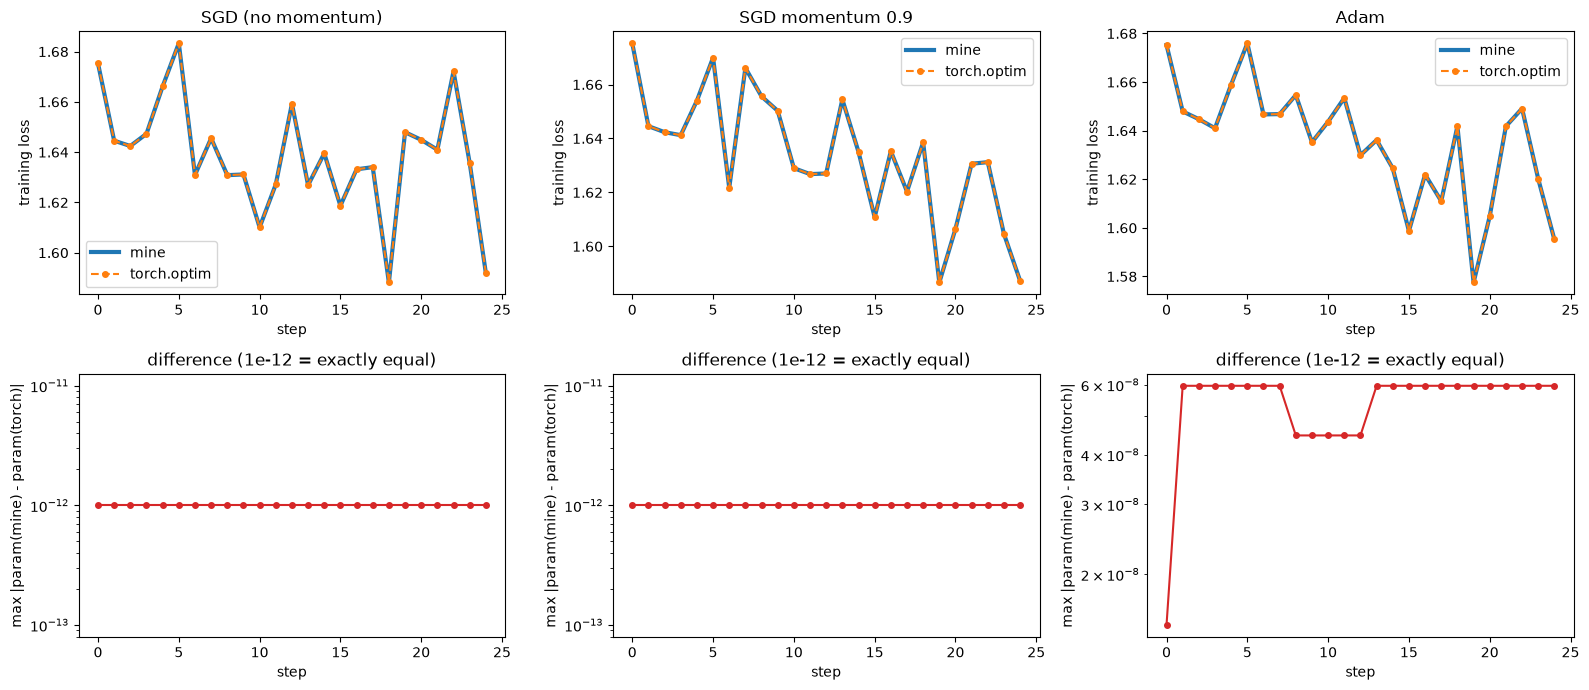

In [15]:
# step-by-step comparison: my optimizer vs the torch.optim one, same model / same data / same init
def trace(mine_fn, ref_fn, steps=25):
    set_seed(1)
    m1 = nn.Sequential(nn.Linear(20, 32), nn.Tanh(), nn.Linear(32, 5)); m2 = copy.deepcopy(m1)
    o1, o2 = mine_fn(m1.parameters()), ref_fn(m2.parameters())
    L1, L2, D = [], [], []
    for _ in range(steps):
        x = torch.randn(64, 20); y = torch.randint(0, 5, (64,))
        losses = []
        for m, o in ((m1, o1), (m2, o2)):
            o.zero_grad(); l = F.cross_entropy(m(x), y); l.backward(); o.step(); losses.append(l.item())
        L1.append(losses[0]); L2.append(losses[1])
        D.append(max((a - b).abs().max().item() for a, b in zip(m1.parameters(), m2.parameters())))
    return L1, L2, D

fig, axs = plt.subplots(2, 3, figsize=(16, 7))
for col, (name, (a, b)) in enumerate(tests.items()):
    L1, L2, D = trace(a, b)
    ax = axs[0, col]
    ax.plot(L1, "-", lw=3, color="C0", label="mine"); ax.plot(L2, "--", lw=1.5, color="C1", marker="o", ms=4, label="torch.optim")
    ax.set(title=name, xlabel="step", ylabel="training loss"); ax.legend()
    ax = axs[1, col]
    ax.semilogy(np.maximum(D, 1e-12), "o-", color="C3", ms=4)
    ax.set(xlabel="step", ylabel="max |param(mine) - param(torch)|", title="difference (1e-12 = exactly equal)")
    #print(f"{name:20s} step-by-step loss: max |mine - torch| = {max(abs(p - q) for p, q in zip(L1, L2)):.2e}")
plt.tight_layout(); plt.show()

**Interpretation (2a).** Both optimizers match the PyTorch reference. SGD and SGD with momentum give exactly the same parameters (difference 0.0) after 25 steps, and Adam differs by only 6e-8, which is float32 round-off from a different order of operations. `torch.allclose` is `True` in all three cases, so the update rules, including Adam's bias correction, are implemented correctly.

**(b)** Trajectories on f(x, y) = ½(x² + 50y²), starting from (10, 1).

**Why conditioning matters.** For $f(x,y)=\tfrac12\,(x^2+50y^2)$ we have $\nabla f=(x,\,50y)$ and Hessian $\mathrm{diag}(1,50)$, i.e. condition number $\kappa=50$. Gradient descent acts on each coordinate independently:
$$x_{t+1}=(1-\eta)\,x_t,\qquad y_{t+1}=(1-50\eta)\,y_t .$$
It converges only if $\eta<2/50=0.04$ (set by the steepest direction), and then the flat direction contracts by $(1-\eta)\ge 0.96$ per step: slow. With $\eta$ close to the limit, $y$ flips sign each step (zig-zag).

For momentum, each coordinate with curvature $\lambda$ follows a linear recurrence that is stable iff $\eta\lambda<2(1+\mu)$ (so $\eta\lambda<3.8$ for $\mu=0.9$, a larger step is allowed). When the roots are complex the iterate oscillates while its amplitude decays by $\sqrt{\mu}\approx0.95$ per step, in every coordinate: this is the spiral/zig-zag path around the minimum. Adam divides each coordinate by the running RMS of its own gradient, so its step size is roughly $\eta$ in every coordinate whatever the curvature; with a fixed $\eta$ it therefore keeps oscillating at a scale of about $\eta$ near the optimum.

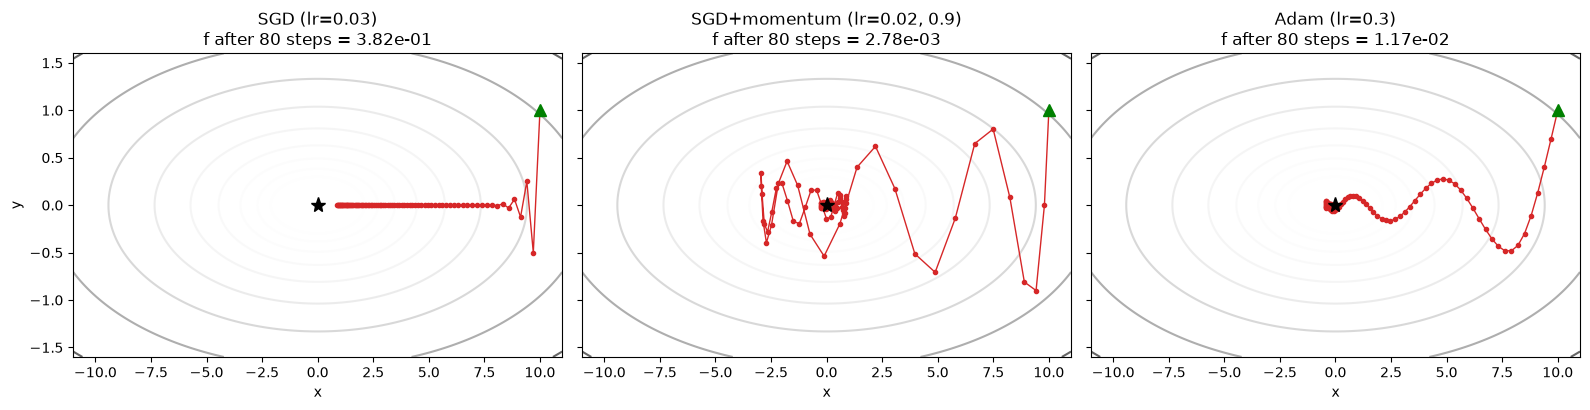

In [16]:
def trajectory(make_opt, steps=80, start=(10., 1.)):
    p = torch.tensor(start, requires_grad=True); opt = make_opt([p]); pts = [p.detach().clone()]
    for _ in range(steps):
        opt.zero_grad(); f = 0.5 * (p[0] ** 2 + 50 * p[1] ** 2); f.backward(); opt.step(); pts.append(p.detach().clone())
    return torch.stack(pts).numpy()

runs = {
    "SGD (lr=0.03)":                trajectory(lambda p: MySGD(p, 0.03, 0.0)),
    "SGD+momentum (lr=0.02, 0.9)":  trajectory(lambda p: MySGD(p, 0.02, 0.9)),
    "Adam (lr=0.3)":                trajectory(lambda p: MyAdam(p, 0.3)),
}
xs, ys = np.meshgrid(np.linspace(-11, 11, 400), np.linspace(-1.6, 1.6, 400))
fig, axs = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, (name, tr) in zip(axs, runs.items()):
    ax.contour(xs, ys, 0.5 * (xs ** 2 + 50 * ys ** 2), levels=np.geomspace(0.5, 120, 12), cmap="Greys", alpha=0.6)
    ax.plot(tr[:, 0], tr[:, 1], "o-", ms=3, lw=1, color="C3"); ax.plot(*tr[0], "g^", ms=9); ax.plot(0, 0, "k*", ms=11)
    f = 0.5 * (tr[:, 0] ** 2 + 50 * tr[:, 1] ** 2)
    ax.set(title=f"{name}\nf after 80 steps = {f[-1]:.2e}", xlabel="x"); 
axs[0].set_ylabel("y"); plt.tight_layout(); plt.show()

**Interpretation (2b).** The function f(x, y) = ½(x² + 50y²) is ill-conditioned: the curvature is 1 along x and 50 along y. Plain SGD is limited by the steep direction (it is only stable for lr < 2/50 = 0.04). With lr = 0.03 the y-coordinate is damped immediately (it is multiplied by −0.5 each step), but x only shrinks by a factor 0.97 per step. SGD therefore crawls along the valley floor and is still at x ≈ 0.9 after 80 steps (f = 0.38). Momentum accumulates the consistent gradient along x and cancels the alternating gradient along y, so it moves much faster (effective step ≈ lr/(1−β) along the valley). It reaches f = 2.8e-3, but it overshoots and zig-zags around the minimum. Adam divides by the running RMS of each coordinate's gradient, so it takes steps of similar size in x and y whatever their curvature. It follows a smooth path towards the minimum (f = 1.2e-2) and with a fixed lr of 0.3 it keeps wobbling slightly around the optimum. After 80 steps momentum was best, then Adam, then plain SGD. This ranking depends on the chosen learning rates, but it shows why adaptive or momentum methods help on ill-conditioned problems.

**(c)** Small CNN (no batch norm) with plain SGD, SGD+momentum (0.9) and Adam at three learning rates each, 6 epochs each.

**Learning-rate sensitivity.** The optimizers differ in how the learning rate $\eta$ maps to an actual step:

* SGD moves by $\eta\,g$; momentum with $\mu=0.9$ by about $\eta\,g/(1-\mu)=10\,\eta\,g$; Adam by about $\eta$ **per parameter**, almost independently of the gradient scale ($|\hat m_t|/\sqrt{\hat v_t}\lesssim1$). Hence the best $\eta$ is larger for plain SGD than for momentum, and much smaller for Adam.
* Too small an $\eta$ makes training very slow; too large an $\eta$ makes the iteration unstable. For a quadratic, gradient descent is stable only if $\eta<2/\lambda_{\max}$, where $\lambda_{\max}$ is the largest curvature; above this the loss grows or stays at chance level ($\ln 10\approx2.303$ for 10 classes).
* The rates are therefore swept on a logarithmic grid (three values per optimizer, a factor of 10 apart) and compared by the final validation accuracy after a fixed budget of 6 epochs; sensitivity is the width of the range of $\eta$ over which an optimizer works well.

The small CNN here has no batch normalization (3 convolution blocks followed by two fully connected layers), so that the effect of $\eta$ is not hidden by normalization.

In [17]:
LRS = {"SGD": [1e-3, 1e-2, 1e-1], "SGD+momentum": [1e-3, 1e-2, 1e-1], "Adam": [1e-4, 1e-3, 1e-2]}
def make_opt(name, params, lr):
    if name == "SGD": return torch.optim.SGD(params, lr=lr)
    if name == "SGD+momentum": return torch.optim.SGD(params, lr=lr, momentum=0.9)
    return torch.optim.Adam(params, lr=lr)

sweep = {}
for name, lrs in LRS.items():
    for lr in lrs:
        set_seed(); m = small_cnn().to(device)
        t0 = time.time(); h = fit(m, make_opt(name, m.parameters(), lr), Xtr_g, Ytr_g, epochs=6)
        sweep[(name, lr)] = h
        print(f"{name:13s} lr={lr:<7g} final val acc {h['val_acc'][-1]:.4f}  final train loss {h['train_loss'][-1]:.3f}  ({time.time()-t0:.0f}s)")

SGD           lr=0.001   final val acc 0.2052  final train loss 2.266  (11s)
SGD           lr=0.01    final val acc 0.4838  final train loss 1.435  (11s)
SGD           lr=0.1     final val acc 0.6812  final train loss 0.717  (11s)
SGD+momentum  lr=0.001   final val acc 0.4960  final train loss 1.415  (12s)
SGD+momentum  lr=0.01    final val acc 0.7350  final train loss 0.641  (12s)
SGD+momentum  lr=0.1     final val acc 0.6114  final train loss 1.008  (12s)
Adam          lr=0.0001  final val acc 0.5978  final train loss 1.131  (13s)
Adam          lr=0.001   final val acc 0.7398  final train loss 0.496  (13s)
Adam          lr=0.01    final val acc 0.1004  final train loss 2.303  (12s)


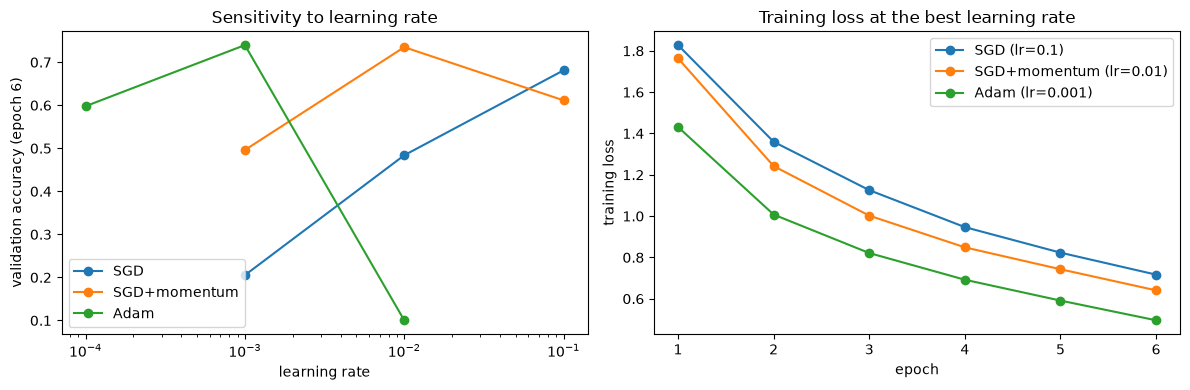

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
best = {}
for k, (name, lrs) in enumerate(LRS.items()):
    accs = [sweep[(name, lr)]["val_acc"][-1] for lr in lrs]
    ax[0].semilogx(lrs, accs, "o-", label=name, color=f"C{k}")
    best[name] = lrs[int(np.argmax(accs))]
ax[0].set(xlabel="learning rate", ylabel="validation accuracy (epoch 6)", title="Sensitivity to learning rate"); ax[0].legend()
for k, name in enumerate(LRS):
    ax[1].plot(range(1, 7), sweep[(name, best[name])]["train_loss"], "o-", label=f"{name} (lr={best[name]:g})", color=f"C{k}")
ax[1].set(xlabel="epoch", ylabel="training loss", title="Training loss at the best learning rate"); ax[1].legend()
plt.tight_layout(); plt.show()

**Interpretation (2c).** The best validation accuracies were Adam at 1e-3 (74.3%), SGD+momentum at 1e-2 (73.5%) and plain SGD at 1e-1 (67.5%). The sensitivity to the learning rate is very different. Plain SGD improves with every increase in the learning rate (20.5% → 48.4% → 67.5%) and its best value is at the edge of my grid, so a still larger rate might be even better. Momentum behaves like a learning rate about 10× larger (the effective step is lr/(1−0.9)), so its best rate is about 10× smaller than SGD's, and lr = 0.1 is already too large (60.7%). Adam has the narrowest good range: 59.8% at 1e-4, 74.3% at 1e-3, and at 1e-2 it fails completely (10.0%, loss 2.303 = ln 10, i.e. chance level). Its default value of 1e-3 works well without tuning, but a rate that is too high breaks it. At the best rate, Adam has the lowest training loss at every epoch (0.50 after 6 epochs against 0.64 for momentum and 0.72 for SGD), and this goes with the highest validation accuracy. These conclusions come from only 6 epochs, 3 learning rates per optimizer and one seed.

## Task 3: Regularization and residual connections
**(a)** Batch-norm CNN trained on only 5k training images. Augmentations are applied on the GPU; **Cutout and mixup are implemented from scratch** in the next cell (`cutout`, `mixup_batch`, `mixup_loss`); flip+crop uses the standard torchvision transforms (`RandomHorizontalFlip`, `RandomCrop` with padding 4). **All combined** = weight decay + dropout + flip+crop + cutout + mixup.

**The regularizers and the generalization gap.** The gap is $\mathrm{acc}_{\text{train}}-\mathrm{acc}_{\text{val}}$ (train accuracy is measured on the clean 5k images in evaluation mode, validation accuracy on the 5k held-out images).

* **Weight decay** ($L_2$ penalty): minimise $L(w)+\dfrac{\lambda}{2}\|w\|^2$; the SGD update becomes $w\leftarrow(1-\eta\lambda)\,w-\eta\nabla L$, i.e. the weights shrink a little at every step.
* **Dropout** (inverted): during training each activation is kept with probability $1-p$ and rescaled, $\tilde h=\dfrac{m\odot h}{1-p}$ with $m_i\sim\mathrm{Bernoulli}(1-p)$; at test time nothing is dropped. It prevents units from co-adapting.
* **Batch normalization:** $\hat x=\dfrac{x-\mu_B}{\sqrt{\sigma_B^2+\varepsilon}},\ \ y=\gamma\hat x+\beta$, with batch statistics in training and running averages at test time.
* **Flip + crop:** random horizontal flip with probability 0.5 and a random $32\times32$ crop of the image padded by 4 pixels. It adds label-preserving variations.
* **Cutout:** $\tilde x=x\odot(1-M)$, where $M$ is a $16\times16$ square mask at a random position (the removed pixels are set to the mean, 0 after normalization).
* **Mixup:** for two training examples $(x_i,y_i),(x_j,y_j)$ and $\lambda\sim\mathrm{Beta}(\alpha,\alpha)$:
$$\tilde x=\lambda x_i+(1-\lambda)x_j,\qquad L=\lambda\,\mathrm{CE}(f(\tilde x),y_i)+(1-\lambda)\,\mathrm{CE}(f(\tilde x),y_j),$$
which is cross-entropy against the mixed label $\lambda\,\mathrm{onehot}(y_i)+(1-\lambda)\,\mathrm{onehot}(y_j)$.

Regularizers act on the generalization gap in different ways: weight decay and dropout constrain the model, while the augmentations and mixup enlarge the effective training set.

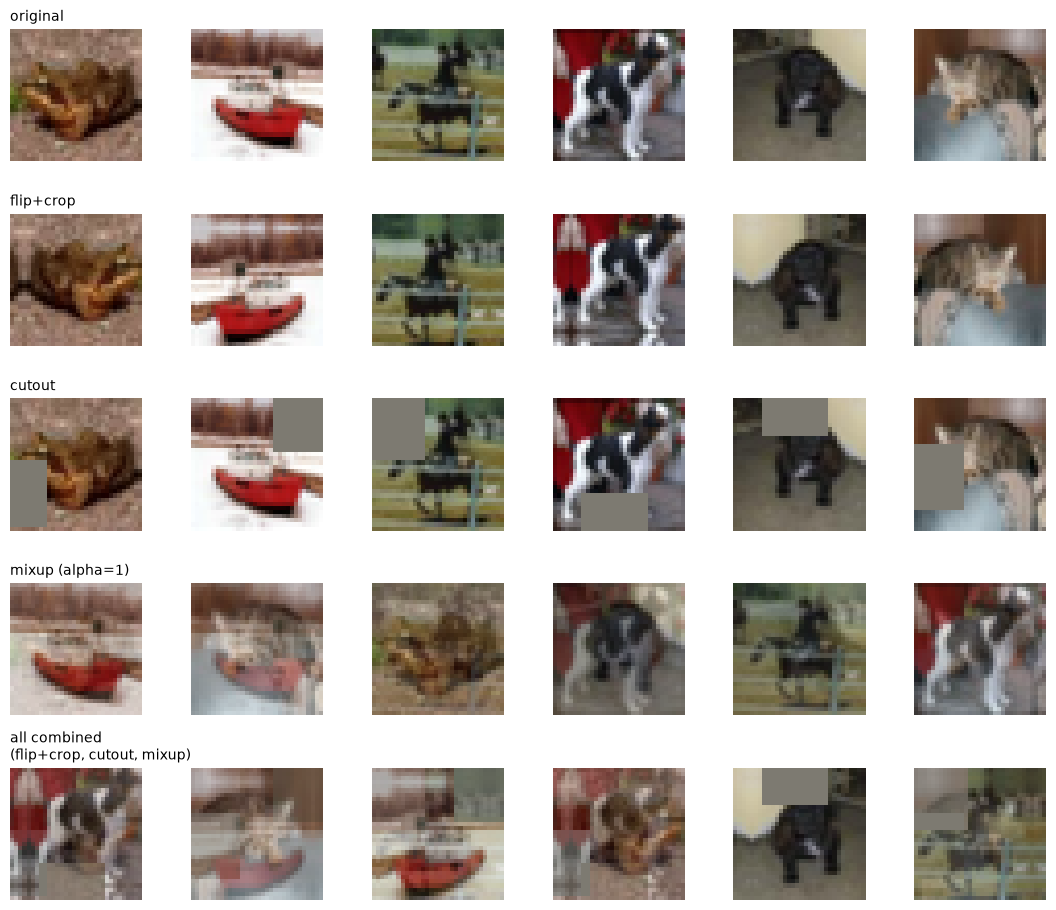

In [19]:

from torchvision.transforms import v2 as T
_flip_crop = T.Compose([T.RandomHorizontalFlip(0.5), T.RandomCrop(32, padding=4, padding_mode="reflect")])
def flip_crop(x):
    return torch.stack([_flip_crop(img) for img in x])


def cutout(x, size=16):
    B, _, H, W = x.shape
    cy = torch.randint(0, H, (B,), device=x.device); cx = torch.randint(0, W, (B,), device=x.device)
    ar = torch.arange(H, device=x.device)[None]
    my = (ar >= cy[:, None] - size // 2) & (ar < cy[:, None] + size // 2)
    mx = (ar >= cx[:, None] - size // 2) & (ar < cx[:, None] + size // 2)
    return x.masked_fill((my[:, :, None] & mx[:, None, :])[:, None], 0.)      # 0 = mean pixel after normalisation

def mixup_batch(x, y, alpha=1.0):
    """Mixup: blend each image with a randomly chosen partner from the same batch.
    lam ~ Beta(alpha, alpha);  x_mix = lam * x + (1 - lam) * x[perm];  returns both label sets and lam."""
    lam = float(np.random.beta(alpha, alpha))
    perm = torch.randperm(len(x), device=x.device)
    return lam * x + (1 - lam) * x[perm], y, y[perm], lam

def mixup_loss(out, y_a, y_b, lam, label_smoothing=0.):
    """Mixup loss: lam * CE(out, y_a) + (1 - lam) * CE(out, y_b)."""
    return (lam * F.cross_entropy(out, y_a, label_smoothing=label_smoothing)
            + (1 - lam) * F.cross_entropy(out, y_b, label_smoothing=label_smoothing))

def all_combined(x):
    """Image-level part of 'all combined': flip+crop, then cutout (mixup is applied afterwards in fit)."""
    return cutout(flip_crop(x))

# quick visual check of every augmentation (6 training images per row)
un = lambda t: (t.cpu() * std[0] + mean[0]).clamp(0, 1).permute(1, 2, 0)
xs_, ys_ = Xtr_g[:6], Ytr_g[:6]
rows_ = [("original", lambda z: z), ("flip+crop", flip_crop), ("cutout", cutout),
         ("mixup (alpha=1)", lambda z: mixup_batch(z, ys_, 1.0)[0]),
         ("all combined\n(flip+crop, cutout, mixup)", lambda z: mixup_batch(all_combined(z), ys_, 1.0)[0])]
fig, axs = plt.subplots(len(rows_), 6, figsize=(11, 9.2))
for r, (nm, fn) in enumerate(rows_):
    set_seed(3); o = fn(xs_)
    for c in range(6): axs[r, c].imshow(un(o[c])); axs[r, c].axis("off")
    axs[r, 0].set_title(nm, loc="left", fontsize=10)
plt.tight_layout(); plt.show()

In [20]:
N5K = 5000
X5, Y5 = Xtr_g[:N5K], Ytr_g[:N5K]
# "all combined" = weight decay 5e-4 + dropout 0.5 + flip+crop + cutout (all_combined) + mixup (alpha=1)
CONFIGS = {
    "baseline":     dict(wd=0,    p=0.0, aug=None,      mix=0.0),
    "weight decay": dict(wd=5e-4, p=0.0, aug=None,      mix=0.0),
    "dropout":      dict(wd=0,    p=0.5, aug=None,      mix=0.0),
    "flip+crop":    dict(wd=0,    p=0.0, aug=flip_crop, mix=0.0),
    "cutout":       dict(wd=0,    p=0.0, aug=cutout,    mix=0.0),
    "mixup":        dict(wd=0,    p=0.0, aug=None,      mix=1.0),
    "all combined": dict(wd=5e-4, p=0.5, aug=all_combined, mix=1.0),
}
EP3 = 40
res3 = {}
for name, c in CONFIGS.items():
    set_seed(); m = small_cnn(bn=True, p_drop=c["p"]).to(device)
    opt = torch.optim.SGD(m.parameters(), lr=0.02, momentum=0.9, weight_decay=c["wd"])
    res3[name] = fit(m, opt, X5, Y5, EP3, augment=c["aug"], mixup_alpha=c["mix"], track_train=True)
    print(f"done {name}")

done baseline
done weight decay
done dropout
done flip+crop
done cutout
done mixup
done all combined


,train acc,val acc,gap (train-val),best val acc
method,,,,
baseline,1.0000,0.6576,0.3424,0.6608
weight decay,1.0000,0.6522,0.3478,0.6566
dropout,0.9312,0.6262,0.3050,0.6546
flip+crop,0.8722,0.6988,0.1734,0.6988
cutout,0.9824,0.6442,0.3382,0.6658
mixup,0.9846,0.6132,0.3714,0.6408
all combined,0.5930,0.5524,0.0406,0.5754


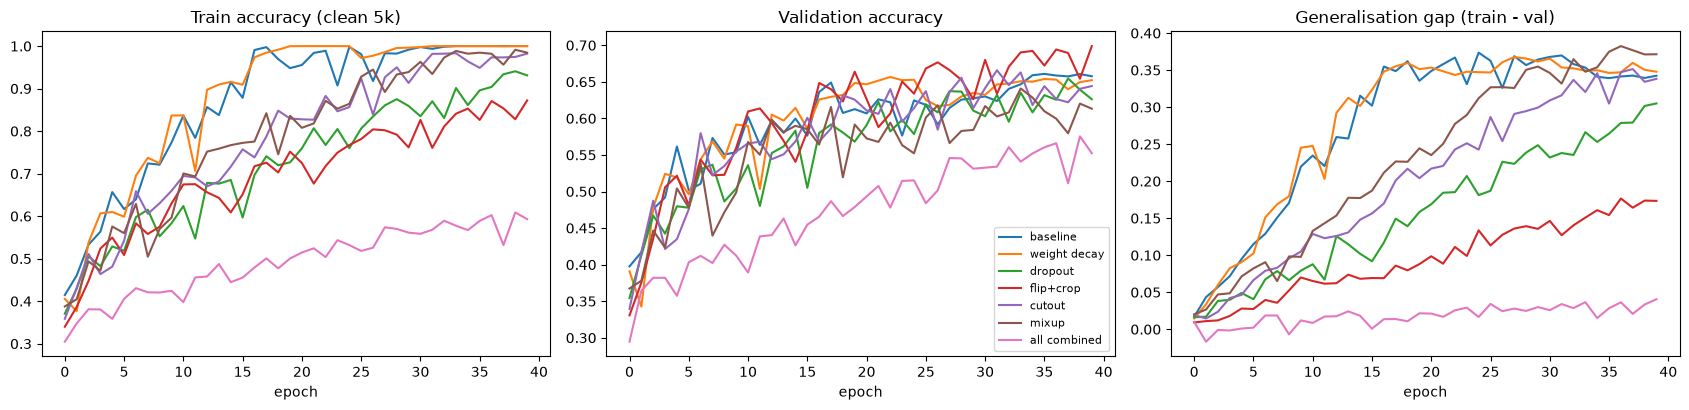

In [21]:
import pandas as pd
rows = [{"method": n, "train acc": h["train_acc"][-1], "val acc": h["val_acc"][-1], "gap (train-val)": h["train_acc"][-1] - h["val_acc"][-1],
         "best val acc": max(h["val_acc"])} for n, h in res3.items()]
df3 = pd.DataFrame(rows).set_index("method"); display(df3.style.format("{:.4f}"))
fig, axs = plt.subplots(1, 3, figsize=(17, 4.2))
for k, (n, h) in enumerate(res3.items()):
    axs[0].plot(h["train_acc"], color=f"C{k}", label=n); axs[1].plot(h["val_acc"], color=f"C{k}", label=n)
    axs[2].plot(np.array(h["train_acc"]) - np.array(h["val_acc"]), color=f"C{k}", label=n)
axs[0].set(title="Train accuracy (clean 5k)", xlabel="epoch"); axs[1].set(title="Validation accuracy", xlabel="epoch")
axs[2].set(title="Generalisation gap (train - val)", xlabel="epoch"); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Interpretation (3a).** With only 5k images the baseline memorises the training set (100% train accuracy) but reaches only 65.8% validation accuracy, a gap of 34.2 points. Weight decay (5e-4) did not change this (65.2%, gap 34.8): the network still fits the training set perfectly. Dropout (p = 0.5) reduced the gap a little (30.5 points) but also lowered the validation accuracy to 62.6%, because it slows down fitting without adding new information. Flip+crop was clearly the most effective method. It is the only one that improves validation accuracy (69.9%, about 4 points above the baseline) and it cuts the gap to 17.3 points. The clean training accuracy falls to 87.2%, so the network can no longer memorise the exact pixels, and the augmented images act like additional training data. Cutout (64.4%, gap 33.8) and mixup (61.3%, gap 37.1) did not help in this setting: they are strong regularizers, and with 5k images and 40 epochs they mostly make fitting harder (cutout) or the training signal noisier (mixup) without improving the validation score. Combining everything gave the smallest gap (4.1 points), but the model underfits (59.3% train, 55.2% validation) and its curves are still rising slowly at epoch 40, so it would need many more epochs. The lesson is that a small gap is not the same as high accuracy: regularization has to be matched to the model size and the training budget, and here only the augmentation that preserves the image content (flip+crop) paid off. The validation curves are noisy (5k validation images, single seed), so differences of 1 point (for example weight decay vs baseline) should not be over-interpreted.

**(b)** CIFAR-style plain vs residual networks of depth 6n+2 (8, 20, 56): three stages (16/32/64 channels), global average pooling, batch norm, Kaiming init. The *only* difference is the shortcut: the residual net adds the block input (parameter-free: stride-2 subsampling and zero-padded channels) to the output of the two convs. Trained on the 45k training images with mixed precision, SGD momentum, no augmentation, so the training loss shows optimisation difficulty.

**Plain vs Residual networks.** A plain block computes $y=\mathcal F(x)$ (two $3\times3$ convolutions with batch norm). A residual block computes
$$y=\mathcal F(x)+x,\qquad \frac{\partial L}{\partial x}=\frac{\partial L}{\partial y}\Big(I+\frac{\partial\mathcal F}{\partial x}\Big).$$
The identity term gives the gradient a direct path to earlier layers, so it cannot vanish through $\mathcal F$, and the block only has to learn a correction to the identity. Without shortcuts, adding layers can make the **training** loss worse, not only the test loss (the *degradation problem*), which is an optimization difficulty and not overfitting.

The depth is $6n+2$: one input convolution, $3$ stages $\times\,n$ blocks $\times\,2$ convolutions, and one linear layer (so $n=1,3,9$ for depths $8,20,56$). When a stage halves the resolution and doubles the channels, the shortcut subsamples with stride 2 and zero-pads the new channels, so it adds **no parameters** and the plain and residual families have identical parameter counts. Convolution and linear weights use Kaiming initialization $\mathcal N(0,\,2/n_{\text{in}})$. The curves show the training loss averaged over each epoch.

In [22]:
class Block(nn.Module):
    def __init__(s, cin, cout, stride, residual):
        super().__init__()
        s.c1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False); s.b1 = nn.BatchNorm2d(cout)
        s.c2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False);     s.b2 = nn.BatchNorm2d(cout)
        s.res, s.stride, s.pad = residual, stride, cout - cin
    def forward(s, x):
        out = s.b2(s.c2(F.relu(s.b1(s.c1(x)))))
        if s.res:
            sc = x[:, :, ::s.stride, ::s.stride] if s.stride > 1 else x
            if s.pad > 0: sc = F.pad(sc, (0, 0, 0, 0, s.pad // 2, s.pad - s.pad // 2))
            out = out + sc
        return F.relu(out)

class CifarNet(nn.Module):
    def __init__(s, n, residual, widths=(16, 32, 64)):
        super().__init__()
        s.conv = nn.Conv2d(3, widths[0], 3, 1, 1, bias=False); s.bn = nn.BatchNorm2d(widths[0])
        layers, cin = [], widths[0]
        for k, w in enumerate(widths):
            for j in range(n):
                layers.append(Block(cin, w, 2 if (j == 0 and k > 0) else 1, residual)); cin = w
        s.blocks = nn.Sequential(*layers); s.fc = nn.Linear(cin, 10)
        for m in s.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)): nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
    def forward(s, x):
        x = F.relu(s.bn(s.conv(x))); x = s.blocks(x)
        return s.fc(x.mean((2, 3)))

for d in (8, 20, 56):
    n = (d - 2) // 6
    print(d, "plain params:", sum(p.numel() for p in CifarNet(n, False).parameters()), "| residual params:", sum(p.numel() for p in CifarNet(n, True).parameters()))

8 plain params: 75290 | residual params: 75290
20 plain params: 269722 | residual params: 269722
56 plain params: 853018 | residual params: 853018


In [23]:
EP3B = 12
res3b = {}
for d in (8, 20, 56):
    for residual in (False, True):
        set_seed(); m = CifarNet((d - 2) // 6, residual).to(device).to(memory_format=torch.channels_last)
        opt = torch.optim.SGD(m.parameters(), lr=0.05, momentum=0.9, weight_decay=1e-4)
        t0 = time.time(); h = fit(m, opt, Xtr_g, Ytr_g, EP3B, amp=True)
        res3b[(d, residual)] = h
        print(f"depth {d:2d} {'residual' if residual else 'plain   '}: final train loss {h['train_loss'][-1]:.3f}  val acc {h['val_acc'][-1]:.4f}  ({time.time()-t0:.0f}s)")

depth  8 plain   : final train loss 0.496  val acc 0.7310  (47s)
depth  8 residual: final train loss 0.497  val acc 0.7536  (51s)
depth 20 plain   : final train loss 0.355  val acc 0.7846  (93s)
depth 20 residual: final train loss 0.245  val acc 0.7398  (103s)
depth 56 plain   : final train loss 1.445  val acc 0.4610  (177s)
depth 56 residual: final train loss 0.250  val acc 0.7058  (177s)


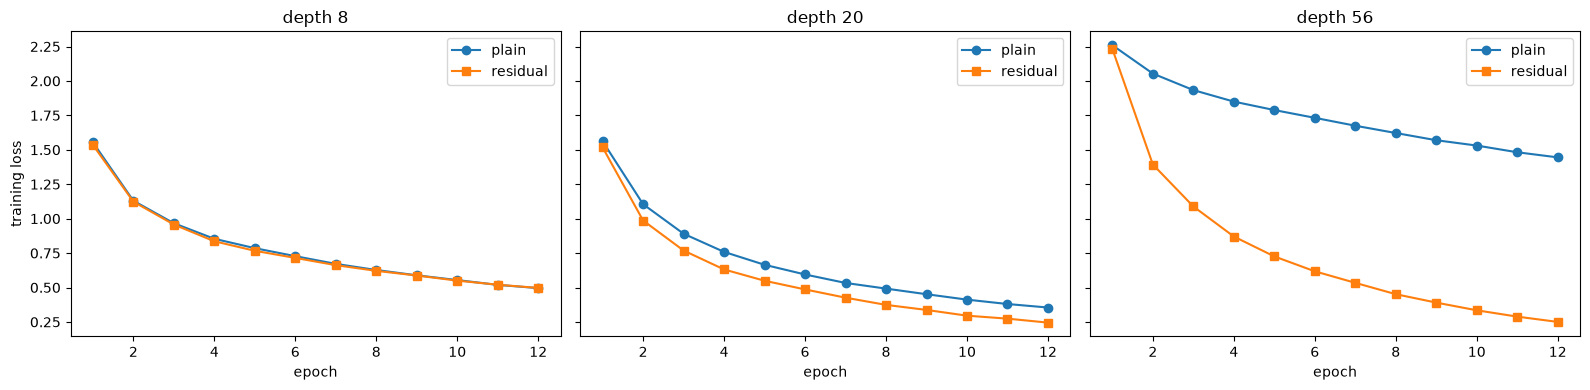

          train loss  val acc
8 plain     0.495647   0.7310
8 res       0.496786   0.7536
20 plain    0.354617   0.7846
20 res      0.245018   0.7398
56 plain    1.444918   0.4610
56 res      0.250149   0.7058


In [24]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, d in zip(axs, (8, 20, 56)):
    ax.plot(range(1, EP3B + 1), res3b[(d, False)]["train_loss"], "o-", label="plain"); ax.plot(range(1, EP3B + 1), res3b[(d, True)]["train_loss"], "s-", label="residual")
    ax.set(title=f"depth {d}", xlabel="epoch"); ax.legend()
axs[0].set_ylabel("training loss"); plt.tight_layout(); plt.show()
print(pd.DataFrame({f"{d} {'res' if r else 'plain'}": {"train loss": h["train_loss"][-1], "val acc": h["val_acc"][-1]} for (d, r), h in res3b.items()}).T)

**Interpretation (3b).** At depth 8 the plain and residual networks have almost identical training loss (0.496 vs 0.497), so the shortcut makes no difference when the network is shallow. At depth 20 the residual network trains faster (final training loss 0.245 vs 0.355). At depth 56 the difference is large: the plain network barely trains (final loss 1.44, 46.1% validation accuracy), while the residual network reaches 0.250 and 70.6%. The plain 56-layer net has the same capacity as the residual one, so it is clearly an optimisation problem, not an overfitting one. A deeper plain network ends up with a *higher training loss* than a shallower one, which is the degradation problem. The identity shortcut gives the gradient a direct path to the early layers and lets each block learn a residual correction around the identity, so adding depth does not hurt. Two remarks: the two families have exactly the same number of parameters (the shortcut is parameter-free), and validation accuracy does not follow training loss exactly. For example at depth 20 the plain net has a higher validation accuracy (78.5% vs 74.0%) even though its training loss is higher. I used no data augmentation and a single seed for 12 epochs, so the residual net fits the training set better but also overfits more. Task 3(b) is about optimisation, so the training loss is the quantity to look at.

## Task 4 (optional): best CNN with <= 500k parameters and <= 20 epochs
Design: a residual CIFAR net (n=3 blocks per stage, widths 20/40/80), SGD+Nesterov with one-cycle LR, weight decay, flip+crop+cutout augmentation, label smoothing, mixed precision. All choices are tuned/compared on the **validation** split; the test set is used once, at the very end, for the final model.

**Theory (4): design choices and protocol.**

* **Label smoothing** with $K=10$ classes replaces the one-hot target by $(1-\epsilon)\,\mathrm{onehot}(y)+\epsilon/K$, which discourages over-confident logits.
* **One-cycle learning rate:** the learning rate rises linearly to a peak and then decays smoothly to almost zero, which allows a large learning rate and converges within a fixed budget of 20 epochs.
* **Nesterov momentum** evaluates the gradient at the look-ahead point $\theta_{t-1}-\eta\mu v_{t-1}$.
* **Parameter budget:** the number of parameters of a residual network with widths $(c_1,c_2,c_3)$ grows with $c^2$, so the widths $(20,40,80)$ were chosen to stay below $500\text{k}$ parameters.
* **Ablation protocol.** Starting from the full model, one design choice is changed at a time and the validation accuracy is compared, $\Delta=\mathrm{acc}_{\text{variant}}-\mathrm{acc}_{\text{full}}$. All decisions use the validation split; the test set is evaluated **once**, for the final model.

In [25]:
EP4, BS4 = 20, 128
steps4 = EP4 * math.ceil(len(Xtr_g) / BS4)
def run4(residual=True, aug=True, wd=5e-4, optname="sgd", ls=0.1, widths=(20, 40, 80)):
    set_seed(); m = CifarNet(3, residual, widths).to(device).to(memory_format=torch.channels_last)
    if optname == "sgd":
        opt = torch.optim.SGD(m.parameters(), lr=0.1, momentum=0.9, nesterov=True, weight_decay=wd)
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=0.1, total_steps=steps4, pct_start=0.25)
    else:
        opt = torch.optim.AdamW(m.parameters(), lr=3e-3, weight_decay=wd * 2)
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=3e-3, total_steps=steps4, pct_start=0.25)
    h = fit(m, opt, Xtr_g, Ytr_g, EP4, bs=BS4, augment=(lambda x: cutout(flip_crop(x))) if aug else None, sched=sched, amp=True, label_smoothing=ls)
    return m, h

print("parameters:", sum(p.numel() for p in CifarNet(3, True, (20, 40, 80)).parameters()))

parameters: 420670


In [26]:
ABL = {
    "full model":             dict(),
    "no shortcut (plain)":    dict(residual=False),
    "no augmentation":        dict(aug=False),
    "no weight decay":        dict(wd=0.0),
    "AdamW instead of SGD":   dict(optname="adamw"),
    "no label smoothing":     dict(ls=0.0),
}
res4, final_model = {}, None
for name, kw in ABL.items():
    t0 = time.time(); m, h = run4(**kw); res4[name] = h
    if name == "full model": final_model = m
    print(f"{name:24s} final val acc {h['val_acc'][-1]:.4f}  best {max(h['val_acc']):.4f}  ({time.time()-t0:.0f}s)")

/tmp/ipykernel_501483/3875961054.py:38: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  if sched is not None: sched.step()


full model               final val acc 0.8900  best 0.8900  (299s)
no shortcut (plain)      final val acc 0.8778  best 0.8778  (295s)
no augmentation          final val acc 0.8534  best 0.8554  (182s)
no weight decay          final val acc 0.8776  best 0.8776  (299s)
AdamW instead of SGD     final val acc 0.8802  best 0.8808  (320s)
no label smoothing       final val acc 0.8902  best 0.8902  (325s)


,val acc (final),delta vs full
full model,0.8900,+0.0000
no shortcut (plain),0.8778,-0.0122
no augmentation,0.8534,-0.0366
no weight decay,0.8776,-0.0124
AdamW instead of SGD,0.8802,-0.0098
no label smoothing,0.8902,+0.0002


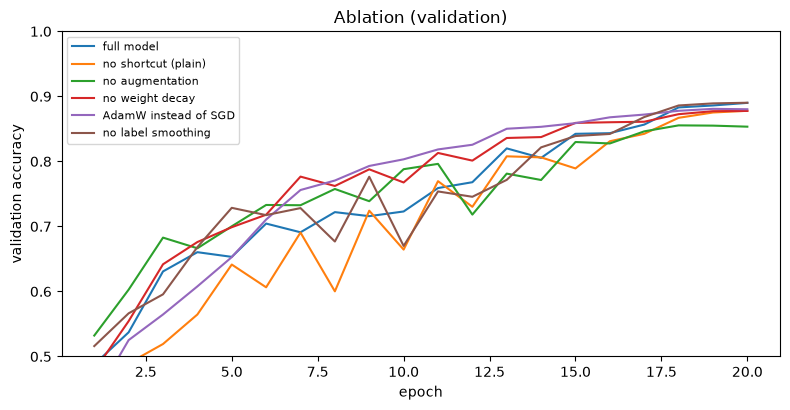

In [27]:
df4 = pd.DataFrame({n: {"val acc (final)": h["val_acc"][-1], "delta vs full": h["val_acc"][-1] - res4["full model"]["val_acc"][-1]} for n, h in res4.items()}).T
display(df4.style.format("{:+.4f}", subset=["delta vs full"]).format("{:.4f}", subset=["val acc (final)"]))
plt.figure(figsize=(8, 4.2))
for n, h in res4.items(): plt.plot(range(1, EP4 + 1), h["val_acc"], label=n)
plt.xlabel("epoch"); plt.ylabel("validation accuracy"); plt.ylim(0.5, 1); plt.legend(fontsize=8); plt.title("Ablation (validation)"); plt.tight_layout(); plt.show()

**Final model: evaluated once on the test set.**

In [28]:
test_acc, test_loss = evaluate(final_model, Xte_g, Yte_g, amp=True)
print(f"FINAL TEST ACCURACY (evaluated once): {test_acc:.4f}")

FINAL TEST ACCURACY (evaluated once): 0.8936


**Interpretation (Task 4).** The final model is a residual network with 420,670 parameters (below the 500k limit), trained for 20 epochs with SGD (Nesterov) and a one-cycle learning rate, weight decay 5e-4, flip+crop+cutout augmentation and label smoothing 0.1. It reached 89.0% validation accuracy and **89.4% test accuracy**, evaluated once, so the validation split gave an honest estimate and I did not overfit to it. In the ablation, removing data augmentation hurt most (−3.7 points), clearly more than any other choice. Removing weight decay (−1.2), removing the shortcut (−1.2) and replacing SGD by AdamW (−1.0) each cost about one point, and removing label smoothing made no difference (+0.02). Augmentation matters most because the network can fit CIFAR-10 easily and needs regularization. The shortcut helps less than in Task 3(b) because a 20-layer network with batch norm is still easy to optimise. Each ablation is a single run, so differences of about 1 point are close to the run-to-run noise: only the effect of augmentation is clearly larger than the noise, and for the shortcut, weight decay and AdamW I can only say that they probably help a little. Label smoothing had no measurable effect in this short, small-model setting.